# Exercise: Matplotlib — Swiss EV Charging Stations

In this exercise you will create EDA plots using **Matplotlib** for the Swiss EV charging stations dataset. Use the object-oriented interface (`fig, ax = plt.subplots()`) throughout.

---
## Tasks
1. **Histogram**: plot the distribution of `power_kw` with 30 bins. Add x-label, y-label and title.
2. **Horizontal bar chart**: show the top 10 cities by station count (sorted descending).
3. **Box plot**: compare `power_kw` across the three `power_type` groups side by side.
4. **Scatter plot**: plot `voltage` vs. `power_kw`. Use different colours for each `power_type`.
5. **Pie chart**: show the share of each `plug_type`. Limit to the top 4 types, group the rest as 'Other'.
6. **Subplots (2×2)**: combine histogram, bar chart, box plot and scatter plot in a single figure.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
warnings.filterwarnings('ignore')

df = pd.read_csv('../data/ev_charging_stations.csv')
print('Shape:', df.shape)
df.head(3)

Shape: (2442, 15)


,evse_id,station_name,street,city,postal_code,lat,lon,power_kw,power_type,amperage,voltage,plug_type,is_open_24h,renewable_energy,auth_mode
0,CH*CCI*E22078,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
1,CH*CCI*E22076,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
2,CH*CCI*E22079,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.23432,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic


### Task 1 — Histogram of `power_kw`

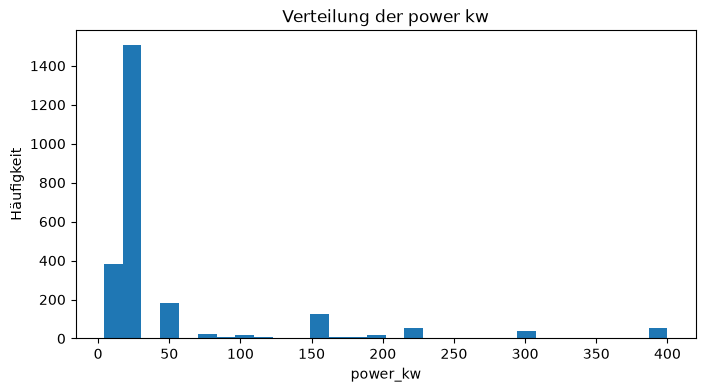

In [12]:
# YOUR CODE HERE
plt.figure(figsize=(8, 4))
plt.hist(df['power_kw'], bins=30)
plt.title('Verteilung der power kw')
plt.xlabel('power_kw')
plt.ylabel('Häufigkeit')
plt.show()


### Task 2 — Horizontal bar chart: top 10 cities

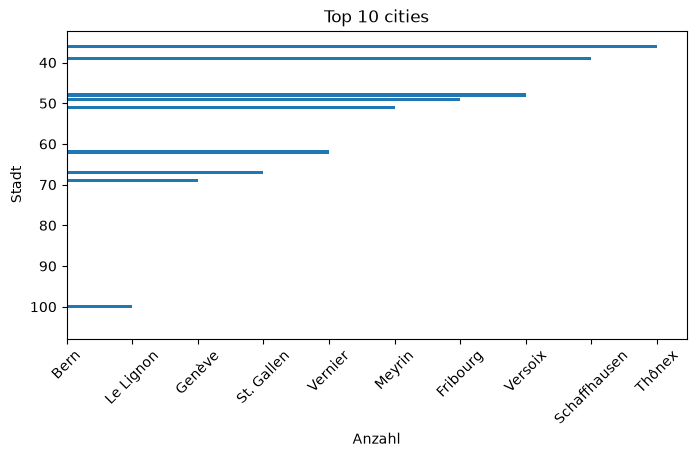

In [54]:
# YOUR CODE HERE
top_cities=df['city'].value_counts().head(10)


plt.figure(figsize=(8, 4))
plt.barh(top_cities.values, top_cities.index)
plt.title('Top 10 cities')
plt.xlabel('Anzahl')
plt.ylabel('Stadt')
plt.gca().invert_yaxis()
plt.xticks(rotation=45)          # Beschriftung schräg, falls sie sich überlappt
plt.show()


### Task 3 — Box plot: `power_kw` by `power_type`

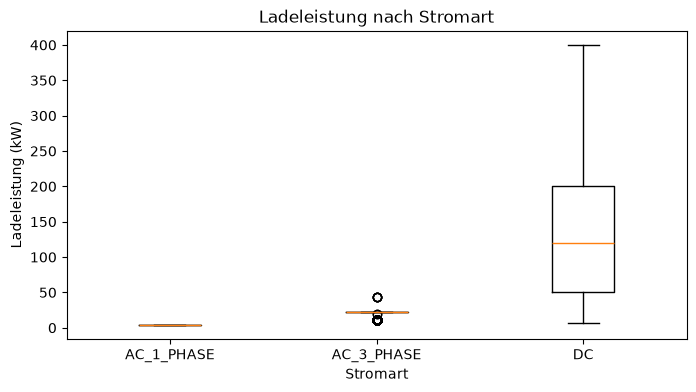

In [73]:
# YOUR CODE HERE
ac1 = df[df['power_type'] == 'AC_1_PHASE']['power_kw']
ac3 = df[df['power_type'] == 'AC_3_PHASE']['power_kw']
dc  = df[df['power_type'] == 'DC']['power_kw']

plt.figure(figsize=(8, 4))
plt.boxplot([ac1, ac3, dc], tick_labels=['AC_1_PHASE', 'AC_3_PHASE', 'DC'])
plt.title('Ladeleistung nach Stromart')
plt.xlabel('Stromart')
plt.ylabel('Ladeleistung (kW)')
plt.show()


### Task 4 — Scatter plot: `voltage` vs. `power_kw` coloured by `power_type`

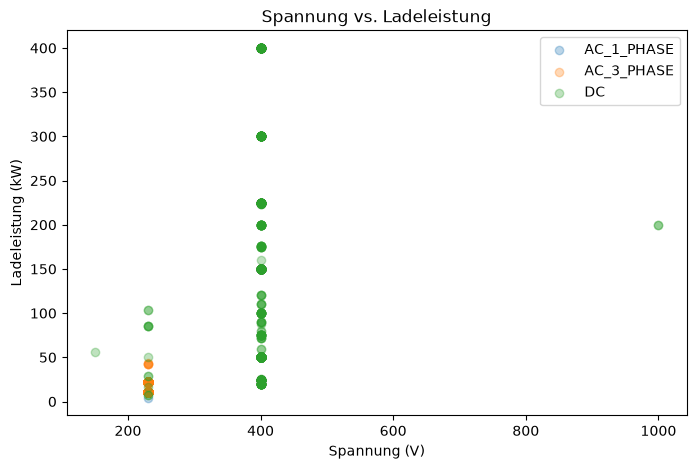

In [93]:
ac1_df = df[df['power_type'] == 'AC_1_PHASE']
ac3_df = df[df['power_type'] == 'AC_3_PHASE']
dc_df  = df[df['power_type'] == 'DC']

plt.figure(figsize=(8, 5))
plt.scatter(ac1_df['voltage'], ac1_df['power_kw'], alpha=0.3, label='AC_1_PHASE')
plt.scatter(ac3_df['voltage'], ac3_df['power_kw'], alpha=0.3, label='AC_3_PHASE')
plt.scatter(dc_df['voltage'],  dc_df['power_kw'],  alpha=0.3, label='DC')
plt.title('Spannung vs. Ladeleistung')
plt.xlabel('Spannung (V)')
plt.ylabel('Ladeleistung (kW)')
plt.legend()
plt.show()


### Task 5 — Pie chart: share of `plug_type`

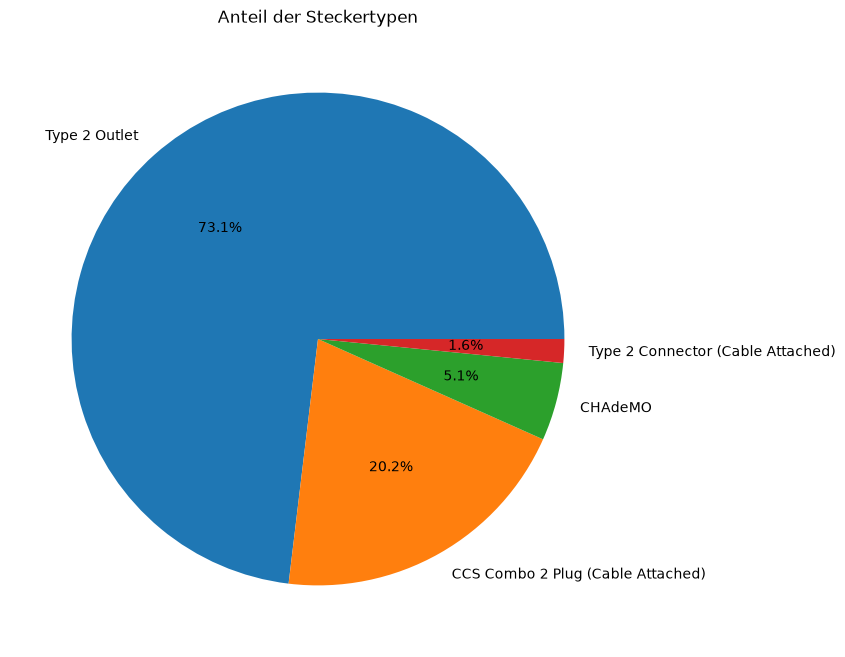

In [ ]:
counts = df['plug_type'].value_counts() #um alle zu holen
top4_counts = counts.head(4) # nur die höchsten 4
other = counts.iloc[4:].sum() #der rest ab Zeile 5
if other > 0:
    top4_counts['Other'] = other #damit falls nichts in other ist nicht ein leeres stück kuchen auftaucht
plt.figure(figsize=(8, 8)) 
plt.pie(top4_counts.values, labels=top4_counts.index, autopct='%1.1f%%')
plt.title('Anteil der Steckertypen')

plt.show()

### Task 6 — Combined 2×2 subplot figure

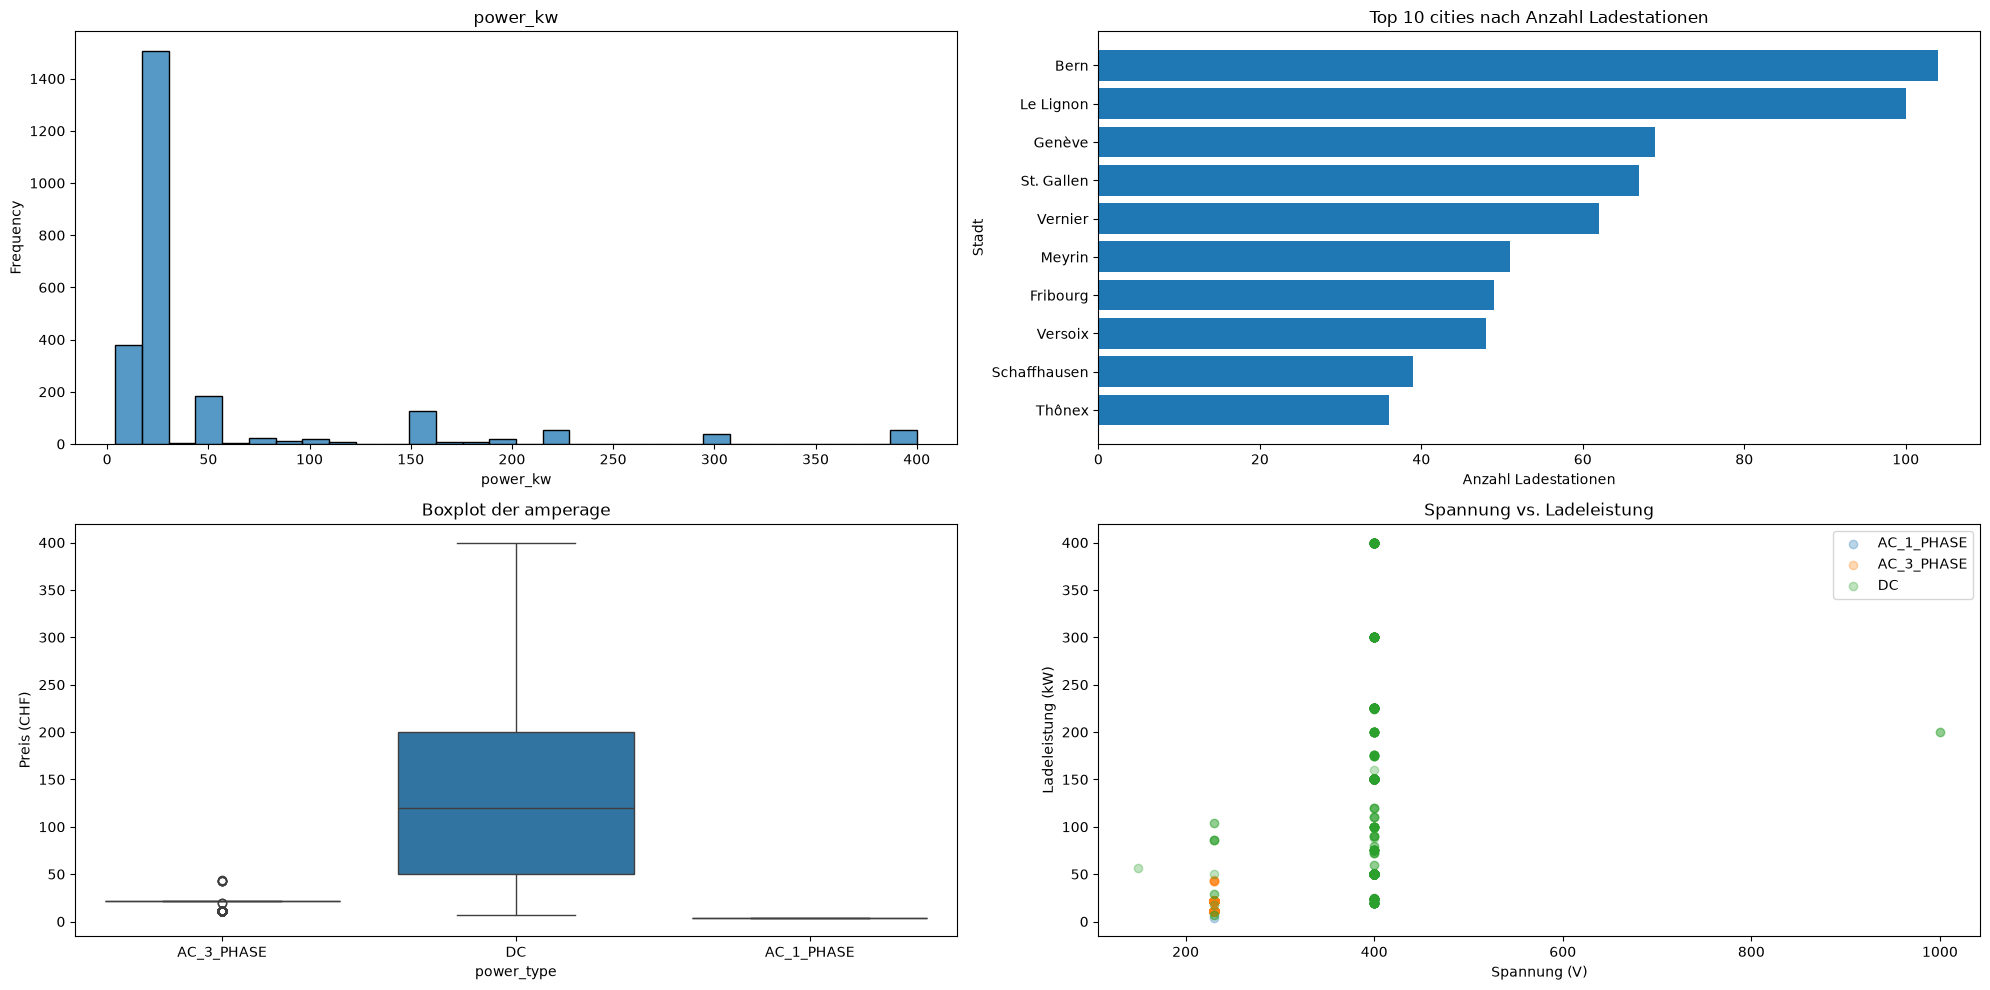

In [138]:
plt.figure(figsize=(20,10))   #das kommt dann aber nur beim ersten histogramm
plt.subplot(2, 2, 1) #heisst-> 1= es soll eine Reihe geben, 2= in dieser Reihe soll es 2 Grafiken geben, 1= jetzt zeichne ich die erste (links).
sns.histplot(data=df, x='power_kw', bins=30) 
plt.title('power_kw')
plt.xlabel('power_kw')
plt.ylabel('Frequency')

plt.subplot(2, 2, 2) #heisst-> 1= es soll eine Reihe geben, 2= in dieser Reihe soll es 2 Grafiken geben, 1= jetzt zeichne ich die erste (links).

top_cities=df['city'].value_counts().head(10) #zuerst zählen und dann variable speichern

plt.barh(top_cities.index, top_cities.values )
plt.title('Top 10 cities nach Anzahl Ladestationen')
plt.xlabel('Anzahl Ladestationen') #x und y sind bei horizontal anzahl / Häufigkeit vertauscht
plt.ylabel('Stadt')
plt.gca().invert_yaxis() #damit es descending ist

plt.subplot(2, 2, 3) #heisst-> 1= es soll eine Reihe geben, 2= in dieser Reihe soll es 2 Grafiken geben, 1= jetzt zeichne ich die erste (links).
sns.boxplot(data=df, x='power_type',y='power_kw') 		#vs matplotlib plt.boxplot(df['price'])
plt.title('Boxplot der amperage')
plt.ylabel('Preis (CHF)')

plt.subplot(2, 2, 4) #heisst-> 1= es soll eine Reihe geben, 2= in dieser Reihe soll es 2 Grafiken geben, 1= jetzt zeichne ich die erste (links).
ac1_df = df[df['power_type'] == 'AC_1_PHASE']
ac3_df = df[df['power_type'] == 'AC_3_PHASE']
dc_df  = df[df['power_type'] == 'DC']

plt.scatter(ac1_df['voltage'], ac1_df['power_kw'], alpha=0.3, label='AC_1_PHASE')
plt.scatter(ac3_df['voltage'], ac3_df['power_kw'], alpha=0.3, label='AC_3_PHASE')
plt.scatter(dc_df['voltage'],  dc_df['power_kw'],  alpha=0.3, label='DC')
plt.title('Spannung vs. Ladeleistung')
plt.xlabel('Spannung (V)')
plt.ylabel('Ladeleistung (kW)')
plt.legend()

plt.tight_layout()
plt.show()



## Jupyter notebook --footer info--
(please always provide this at the end of each notebook)

In [139]:
import os, platform, socket
from platform import python_version
from datetime import datetime
print('------------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('------------------------------------')

------------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-11-06 20:27:02
Python Version: 3.11.18
------------------------------------
